# Task 1: Analysis of Drug–Target Datasets

## Objective: 
Explore score distributions and observation of the drug-target pairs. Explain the main features and key differences between DAVIS and KIBA.

## Notebook structure
This ipynb will be split into 5 parts:
1. DAVIS dataset
2. KIBA dataset
3. DAVIS vs KIBA comparison
4. Comparison with CSV files for both DAVIS and KIBA

For parts 1 to 3, the data used is from the [data github repo](https://github.com/hkmztrk/DeepDTA/tree/master/data)
The CSV files for part 4 were taken from [the kaggle dataset](https://www.kaggle.com/datasets/rajaryan2315/davis-and-kiba-datasets)

## Import and file locations

In [14]:
import os, json, pickle, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, leaves_list
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog('rdApp.*'); warnings.filterwarnings('ignore')

SEED = 6767
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 160, 'display.max_colwidth', 70)

DAVIS_DIR = '../Data/davis/'
KIBA_DIR = '../Data/kiba/'

LIMIT_KD_NM = 10_000.0
LIMIT_PKD   = 5

## Helper functions

Deduplication helpers

In [15]:
def canon(smi):
    """
    put the SMILES into canonical form, but if cant find then return the original
    """
    m = Chem.MolFromSmiles(smi)
    return Chem.MolToSmiles(m) if m is not None else smi

def counts(df, lig='lig_key', tgt='tgt_key'):
    """
    num unique ligands, targets, and pairs
    """
    return dict(ligands = df[lig].nunique(), 
                targets = df[tgt].nunique(), 
                observed_pairs = len(df))

def clean_and_dedup(long_df, score_col, positive_required, transform=None):
    """
    long_df cols should be 
        ligand_cid,
        target,
        smiles,
        sequence, 
        <score_col>

    out: out - cleaned dataset where one row = one ligand-target pair
    table: table - summary of how many ligands, targets, and pairs remain after each cleaning step
    """
    
    log = []
    df = long_df.copy()
    df['lig_key'] = df.ligand_cid; df['tgt_key'] = df.target
    log.append(('0. raw records (matrix cells including missing)', dict(ligands=df.lig_key.nunique(), targets=df.tgt_key.nunique(), observed_pairs=len(df))))
    df = df[df[score_col].notna()]
    
    log.append(('1. observed values (not NaN)', counts(df)))
    fin = np.isfinite(df[score_col]); n_nonfinite = int((~fin).sum()); df = df[fin]
    
    log.append((f'2. finite scores (dropped {n_nonfinite})', counts(df)))
    
    if positive_required:
        pos = df[score_col] > 0; n_nonpos = int((~pos).sum()); df = df[pos]
        log.append((f'3. Kd > 0 (dropped {n_nonpos})', counts(df)))
    df = df.assign(score=transform(df[score_col]) if transform else df[score_col])
    
    # --- de-duplication keys ---
    # apply canon to SMILES then use that as the key
    canonMap = {x: canon(x) for x in df.smiles.unique()}
    df['lig_key'] = df.smiles.map(canonMap)
    df['tgt_key'] = df.sequence
    log.append(('4. keyed by canonical SMILES / sequence (before averaging)', counts(df)))
    g = df.groupby(['lig_key', 'tgt_key'])
    out = g.agg(score=('score', 'mean'), n_repeats=('score', 'size'), score_min=('score', 'min'), score_max=('score', 'max'),
                ligand_cid=('ligand_cid', 'first'), target=('target', 'first')).reset_index()
    out['score_spread'] = out.score_max - out.score_min
    log.append(('5. deduplicated, repeats averaged', counts(out)))
    table = pd.DataFrame({k: v for k, v in log}).T
    return out, table


## Part 1: DAVIS dataset

### 1.1 Load dataset variables

In [16]:
ligands = json.load(open(os.path.join(DAVIS_DIR, 'ligands_can.txt')))
proteins = json.load(open(os.path.join(DAVIS_DIR, 'proteins.txt')))
with open(f'{DAVIS_DIR}/Y', 'rb') as temp:
    davis_Y = pickle.load(temp, encoding='latin1')

print("pickled davis_Y shape:", davis_Y.shape, davis_Y.dtype)
print("ligands:", len(ligands), "proteins:", len(proteins))
lig_ids = list(ligands)
tgt_names = list(proteins)

raw_df = pd.DataFrame(davis_Y, index=lig_ids, columns=tgt_names)
long_raw = raw_df.rename_axis(index='ligand_cid', columns='target').reset_index().melt(id_vars='ligand_cid', var_name='target', value_name='Kd_nM')
long_raw['smiles'] = long_raw.ligand_cid.map(ligands)
long_raw['sequence'] = long_raw.target.map(proteins)
short = lambda d: d.assign(sequence=d.sequence.str[:30] + '...', smiles=d.smiles.str[:40] + '...')

print("---\nfirst 5 rows of long_raw:")
display(short(long_raw).head(5))
print("top left corner of Kd matrix:")
display(raw_df.iloc[:5, :6])

pickled davis_Y shape: (68, 442) float64
ligands: 68 proteins: 442
---
first 5 rows of long_raw:


,ligand_cid,target,Kd_nM,smiles,sequence
0,11314340,AAK1,43.0,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGL...
1,24889392,AAK1,10000.0,CC(C)(C)C1=CC(=NO1)NC(=O)NC2=CC=C(C=C2)C...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGL...
2,11409972,AAK1,10000.0,CCN1CCN(CC1)CC2=C(C=C(C=C2)NC(=O)NC3=CC=...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGL...
3,11338033,AAK1,10000.0,C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGL...
4,10184653,AAK1,10000.0,CN(C)CC=CC(=O)NC1=C(C=C2C(=C1)C(=NC=N2)N...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGL...


top left corner of Kd matrix:


,AAK1,ABL1(E255K),ABL1(F317I),ABL1(F317I)p,ABL1(F317L),ABL1(F317L)p
11314340,43.0,10000.0,10000.0,10000.0,10000.00,10000.0
24889392,10000.0,10000.0,10000.0,10000.0,10000.00,10000.0
11409972,10000.0,75.0,1.9,13.0,0.77,13.0
11338033,10000.0,10000.0,10000.0,10000.0,10000.00,10000.0
10184653,10000.0,420.0,2900.0,750.0,580.00,230.0


### 1.2 Dataset cleaning and deduplication

#### Cleaning steps
1. count observed = num of cells in matrix not NaN
2. remove and NaN or infinite values
3. remove negative Kd
4. convert Kd to pKd
5. deduplicate by using the canonical SMILES and targets
* rows with identical (ligand, target) pairs are averaged in pKd space

the functions are defined earlier under Helper Functions

In [17]:
davis_clean, davis_log = clean_and_dedup(long_raw, 'Kd_nM', positive_required = True, transform = lambda kd: 9 - np.log10(kd))
display(davis_log)
print('(ligand, target) cells that were averaged from repeats:', int((davis_clean.n_repeats > 1).sum()))

,ligands,targets,observed_pairs
0. raw records (matrix cells including missing),68,442,30056
1. observed values (not NaN),68,442,30056
2. finite scores (dropped 0),68,442,30056
3. Kd > 0 (dropped 0),68,442,30056
4. keyed by canonical SMILES / sequence (before averaging),68,379,30056
"5. deduplicated, repeats averaged",68,379,25772


(ligand, target) cells that were averaged from repeats: 1224


Compare original values with deduplicated values

In [23]:
orig, dedup = davis_log.loc['1. observed values (not NaN)'], davis_log.iloc[-1]
cells_all = lambda r: r.ligands * r.targets

summary = pd.DataFrame({'original': orig, 'deduplicated': dedup}).astype(float)
display(summary.style.format('{:.0f}'))

,original,deduplicated
ligands,68,68
targets,442,379
observed_pairs,30056,25772


### 1.3 Rebuild deduplicated matrix

In [26]:
def to_matrix(clean_data, row = "lig_key", col = "tgt_key", row_label = "ligand_cid", col_label = "target"):
    # Create a matrix of scores, with ligands as rows and targets as columns
    matrix = clean_data.pivot(
        index = row,
        columns = col,
        values = "score"
    )

    ligand_labels = clean_data.drop_duplicates(row).set_index(row)[row_label]
    target_labels = clean_data.drop_duplicates(col).set_index(col)[col_label]

    # Replace the ID with labels
    matrix.index = matrix.index.map(ligand_labels)
    matrix.columns = matrix.columns.map(target_labels)

    return matrix


def sparsity(matrix):
    # num missing / total
    missing_values = matrix.isna().sum().sum()
    total_values = matrix.size
    return missing_values / total_values


# Create the pKd matrix (ligands × targets)
pkd_matrix = to_matrix(davis_clean)

# Display basic information about the matrix
minimum_pkd = np.nanmin(pkd_matrix.values)
maximum_pkd = np.nanmax(pkd_matrix.values)

print("pKd matrix shape:", pkd_matrix.shape)
print("Sparsity:", round(sparsity(pkd_matrix), 3))
print("Minimum pKd:", round(minimum_pkd, 3))
print("Maximum pKd:", round(maximum_pkd, 3))

# Save the matrix to a CSV file
os.makedirs("data/processed", exist_ok=True)

pkd_matrix.to_csv("data/processed/davis_pkd_clean.csv")

# Extract all individual pKd scores
scores = davis_clean["score"].values

pKd matrix shape: (68, 379)
Sparsity: 0.0
Minimum pKd: 5.0
Maximum pKd: 10.62


### 1.4 Visualization for DAVIS
#### Ligand and target heatmap

use hierarchical clustering to reorder the rows and columns to make block structure clear
any missing values are greyed out

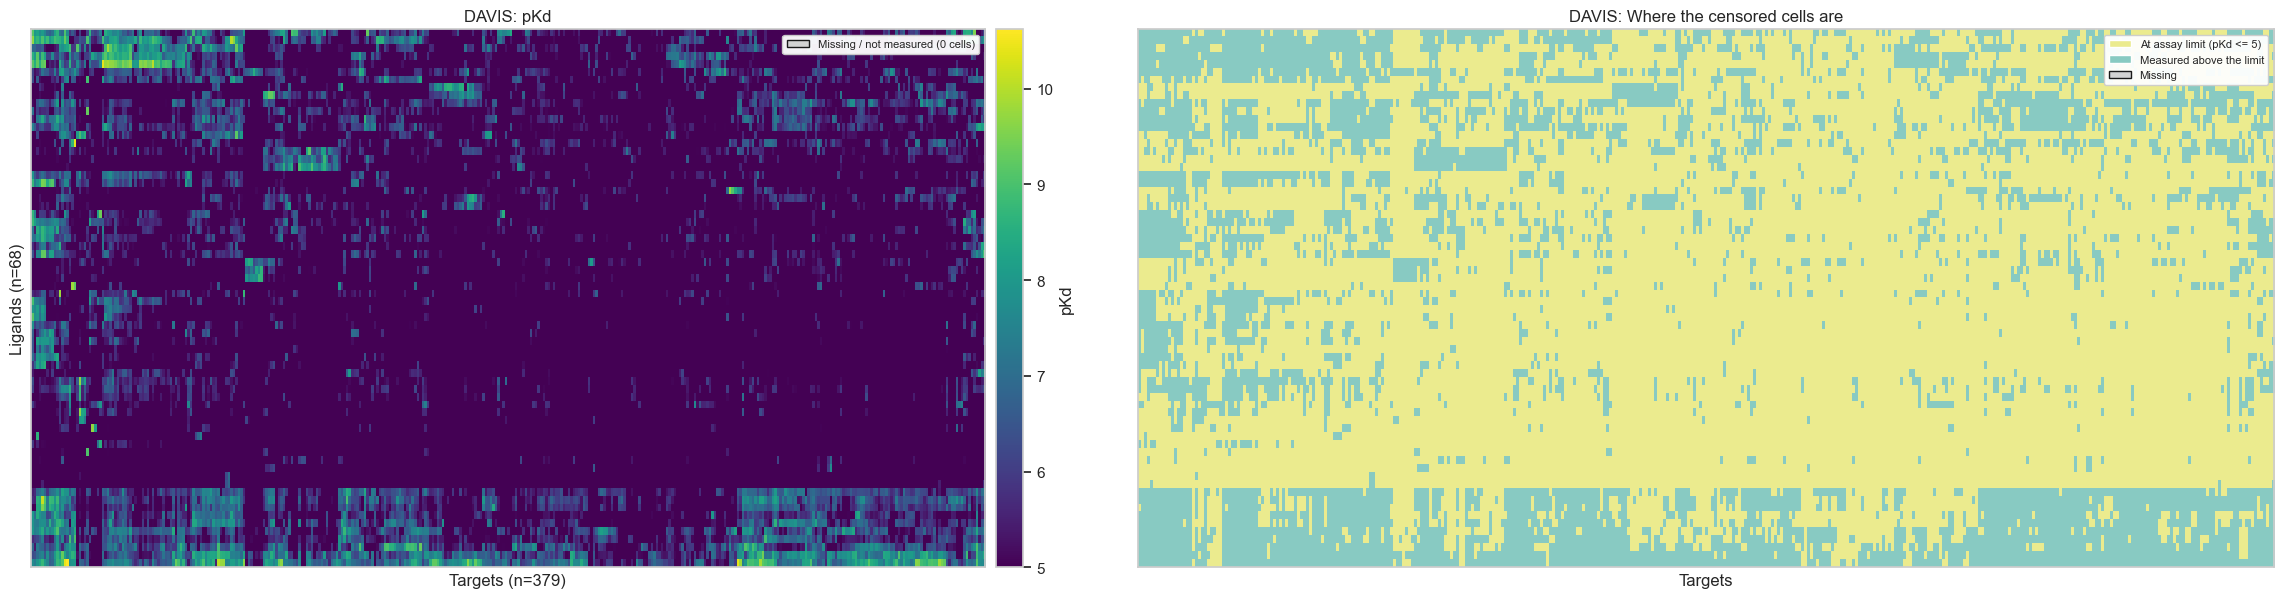

In [30]:
def cluster_order(matrix):
    # Fill missing values with the overall mean for clustering
    filled_matrix = matrix.fillna(np.nanmean(matrix.values))

    # Determine the clustering order for ligands and targets
    rows = leaves_list(linkage(filled_matrix.values, method="average"))

    cols = leaves_list(linkage(filled_matrix.values.T, method="average"))

    # Reorder the matrix according to the clustering results
    return matrix.iloc[rows, cols]


def plot_heatmap(matrix, title, limit_pkd = None, cmap = "viridis", vlabel = "pKd", figsize = (23, 6.15)):

    # reorder with hierarchical clustering: groups similar ligand and targets together
    ordered_matrix = cluster_order(matrix)

    # Count missing measurements
    missing_count = int(matrix.isna().sum().sum())
    has_missing_values = missing_count > 0

    # Decide whether one or two plots are needed
    number_of_plots = (2 if limit_pkd is not None or has_missing_values else 1)

    fig, axes = plt.subplots(
        1, number_of_plots,
        figsize = figsize,
        squeeze = False
    )
    axes = axes[0]

    # Set the colour for missing values in the main heatmap
    heatmap_colours = plt.get_cmap(cmap).copy()
    heatmap_colours.set_bad("lightgrey")

    # Plot the pKd values
    heatmap = axes[0].imshow(
        np.ma.masked_invalid(ordered_matrix.values),
        aspect = "auto",
        cmap = heatmap_colours,
        interpolation = "nearest"
    )

    # Add a colour bar to show the pKd scale
    colourbar = fig.colorbar(heatmap, ax=axes[0], pad=0.01)
    colourbar.set_label(vlabel)

    # Explain the grey cells in the legend
    axes[0].legend(
        handles=[
            Patch(
                facecolor="lightgrey",
                edgecolor="k",
                label=f"Missing / not measured ({missing_count:,} cells)"
            )
        ],
        loc="upper right",
        fontsize=8,
        framealpha=0.95
    )

    # Label the main heatmap
    axes[0].set_title(f"{title}: {vlabel}")
    axes[0].set_xlabel(f"Targets (n={matrix.shape[1]})")
    axes[0].set_ylabel(f"Ligands (n={matrix.shape[0]:,})")

    # Hide tick labels because the matrix may contain many rows and columns
    axes[0].set_xticks([])
    axes[0].set_yticks([])

    # Show measurements <= assay limit
    # show those that have weak binding
    if limit_pkd is not None:

        # Start by classifying all cells as measured above the limit
        assay_limit_categories = np.zeros(ordered_matrix.shape)

        # Mark values at or below the assay limit
        assay_limit_categories[
            ordered_matrix.values <= limit_pkd + 1e-9
        ] = 1.0

        # Preserve missing values
        assay_limit_categories[
            np.isnan(ordered_matrix.values)
        ] = np.nan

        # Assign colours to the two measurement categories
        assay_colours = ListedColormap(["#88cac2", "#ebeb8e"])
        assay_colours.set_bad("lightgrey")

        # Plot the assay-limit classification
        axes[1].imshow(
            np.ma.masked_invalid(assay_limit_categories),
            aspect = "auto",
            cmap = assay_colours,
            interpolation = "nearest",
            vmin = 0,
            vmax = 1
        )

        # Explain the assay-limit categories
        axes[1].legend(
            handles=[
                Patch(
                    facecolor = "#ebeb8e",
                    label=f"At assay limit (pKd <= {limit_pkd:g})"
                ),
                Patch(
                    facecolor="#88cac2",
                    label="Measured above the limit"
                ),
                Patch(
                    facecolor="lightgrey",
                    edgecolor="k",
                    label="Missing"
                )
            ],
            loc = "upper right",
            fontsize = 8,
            framealpha = 0.95
        )

        axes[1].set_title(
            f"{title}: Where the censored cells are"
        )
        axes[1].set_xlabel("Targets")
        axes[1].set_xticks([])
        axes[1].set_yticks([])

    # If no assay limit is provided, show observed versus missing values
    elif has_missing_values:

        # Mark observed cells as 1 and missing cells as 0
        observation_mask = (
            ~np.isnan(ordered_matrix.values)
        ).astype(float)

        # Plot the observation mask
        axes[1].imshow(
            observation_mask,
            aspect = "auto",
            cmap = ListedColormap(["lightgrey", "#264653"]),
            interpolation = "nearest",
            vmin = 0,
            vmax = 1
        )

        # Explain the observed and missing categories
        axes[1].legend(
            handles=[
                Patch(
                    facecolor="#264653",
                    label=f"Observed ({matrix.size - missing_count:,})"
                ),
                Patch(
                    facecolor="lightgrey",
                    edgecolor="k",
                    label=f"Missing ({missing_count:,})"
                )
            ],
            loc = "upper right",
            fontsize = 8,
            framealpha = 0.95
        )

        # Display the proportion of missing measurements
        sparsity = missing_count / matrix.size

        axes[1].set_title(
            f"{title}: Observation mask (sparsity {sparsity:.1%})"
        )
        axes[1].set_xlabel("Targets")
        axes[1].set_xticks([])
        axes[1].set_yticks([])

    # Adjust spacing and display the plots
    plt.tight_layout()
    plt.show()


# Plot the DAVIS dataset
plot_heatmap(pkd_matrix, "DAVIS", limit_pkd=LIMIT_PKD)

#### Score Distribution (KDE plot)

Left: histogram of log counts

Right: KDE of all observed pKd with comparison with those above the limit

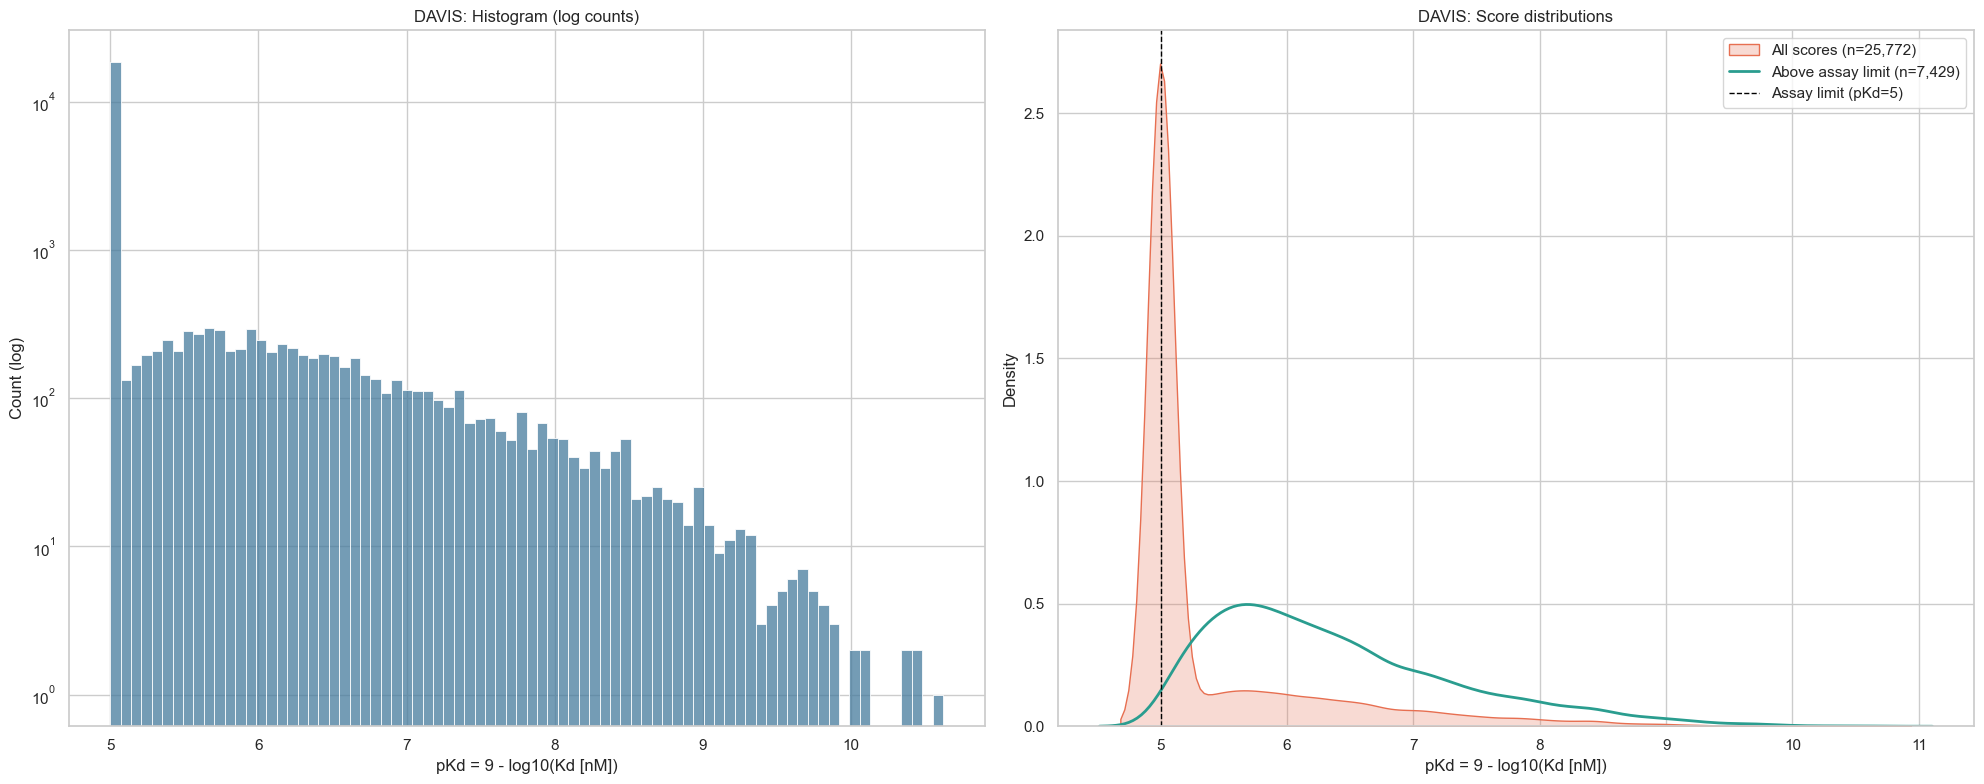

In [31]:
def plot_distribution(values, title, xlabel, limit = None):
 
    # Choose the number of plots depending on whether an assay limit is provided
    number_of_plots = 2 if limit is not None else 2

    fig, axes = plt.subplots(
        1,
        number_of_plots,
        figsize = (20, 8)
    )

    # Left: Histogram of all observed scores
    sns.histplot(
        values,
        bins = 80,
        ax = axes[0],
        color = "#457b9d"
    )

    # Use a log scale to make small counts visible
    axes[0].set_yscale("log")
    axes[0].set_title(f"{title}: Histogram (log counts)")
    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel("Count (log)")

    # Right: KDE distributions

    # Show the density distribution of all observed scores
    sns.kdeplot(
        values,
        ax = axes[1],
        fill = True,
        color = "#e76f51",
        alpha = 0.25,
        bw_adjust = 1.0,
        label = f"All scores (n={len(values):,})"
    )

    # compare scores above assay limit
    if limit is not None:

        # get those above assay limit
        above_limit_values = values[values > limit + 1e-9]

        if len(above_limit_values) > 1:
            sns.kdeplot(
                above_limit_values,
                ax = axes[1],
                color = "#2a9d8f",
                linewidth = 2,
                bw_adjust = 1.0,
                label = f"Above assay limit (n={len(above_limit_values):,})"
            )

        # Mark the assay limit with a vertical dashed line
        axes[1].axvline(
            limit,
            color = "black",
            linestyle = "--",
            linewidth = 1,
            label = f"Assay limit (pKd={limit:g})"
        )

    # Add labels and legend to the combined density plot
    axes[1].set_title(f"{title}: Score distributions")
    axes[1].set_xlabel(xlabel)
    axes[1].set_ylabel("Density")
    axes[1].legend()

    # Adjust spacing and display both plots
    plt.tight_layout()
    plt.show()


# Plot the DAVIS score distribution
plot_distribution(
    scores,
    "DAVIS",
    "pKd = 9 - log10(Kd [nM])",
    limit=LIMIT_PKD
)

#### Binding affinity and assay limits analysis
1. Show number of values at the assay limit
2. summarise the pKd values across different affinity ranges. 
3. Calculate number of ligands and targets at 95% and 100% of the limit.
4. Measure the MSE of predicting pKd = 5 vs the global mean

In [ ]:
# 1. original Kd measurements

# Extract measured Kd values, excluding missing entries
raw_kd_values = long_raw.Kd_nM.dropna().values

# Identify measurements at the assay limit (10,000 nM)
at_assay_limit = np.isclose(raw_kd_values, LIMIT_KD_NM)

print(f"Total observed measurements: {len(raw_kd_values):,}")

print(
    f"Measurements at the assay limit: "
    f"{at_assay_limit.sum():,} "
    f"({at_assay_limit.mean():.1%})"
)

# Count measurements above the assay limit
measurements_above_limit = raw_kd_values > LIMIT_KD_NM

print(
    f"Measurements above 10,000 nM: "
    f"{measurements_above_limit.sum():,}"
)

# count distinct Kd values before and after excluding limit
unique_kd_values = np.unique(raw_kd_values)
unique_kd_below_limit = np.unique(raw_kd_values[~at_assay_limit])

print(
    f"Distinct Kd values (all / excluding limit): "
    f"{len(unique_kd_values):,} / "
    f"{len(unique_kd_below_limit):,}"
)

# Find the smallest Kd, which represents the strongest measured binder
strongest_binding_kd = raw_kd_values.min()
strongest_binding_pkd = 9 - np.log10(strongest_binding_kd)

print(
    f"Strongest measured binder: "
    f"Kd = {strongest_binding_kd:g} nM "
    f"(pKd = {strongest_binding_pkd:.2f})"
)


# 2. distribution of binding affinities
print("---")
print("Share of deduplicated cells by affinity band:")

# Group pKd scores into affinity ranges
affinity_bands = pd.cut(
    scores,
    bins = [-np.inf, 5 + 1e-9, 6, 7, 8, 9, np.inf],
    labels = [
        "pKd=5 (limit)",
        "5-6 (1-10 uM)",
        "6-7 (0.1-1 uM)",
        "7-8 (10-100 nM)",
        "8-9 (1-10 nM)",
        ">9 (<1 nM)"
    ]
)

# Count measurements in each affinity band
band_summary = (
    affinity_bands
    .value_counts()
    .sort_index()
    .to_frame("cells")
)

# Calculate the proportion of measurements in each band
band_summary["share"] = (band_summary["cells"] / band_summary["cells"].sum()).round(4)
display(band_summary)


# 3. ligands and targets dominated by the limit

# Mark cells at or below the pKd assay limit
at_limit_mask = pkd_matrix <= LIMIT_PKD + 1e-9

# Calculate the fraction of cells at the limit for each ligand
fraction_at_limit_per_ligand = at_limit_mask.mean(axis=1)

# Calculate the fraction of cells at the limit for each target
fraction_at_limit_per_target = at_limit_mask.mean(axis=0)

# Count ligands and targets with at least 95% of cells at the limit
ligands_mostly_at_limit = (
    fraction_at_limit_per_ligand >= 0.95
)

targets_mostly_at_limit = (
    fraction_at_limit_per_target >= 0.95
)

print(
    f"Ligands with >=95% of cells at the limit: "
    f"{ligands_mostly_at_limit.sum()} "
    f"of {len(fraction_at_limit_per_ligand)}"
)

print(
    f"Targets with >=95% of cells at the limit: "
    f"{targets_mostly_at_limit.sum()} "
    f"of {len(fraction_at_limit_per_target)}"
)

# Count targets whose cells are all at or below the limit
targets_entirely_at_limit = (fraction_at_limit_per_target == 1)

print(f"Targets with 100% of cells at the limit: {targets_entirely_at_limit.sum()}")


# 4. compare with and without limit values
# keep scores above limit
scores_above_limit = scores[scores > LIMIT_PKD + 1e-9]

print("---")
print(f"All scores: mean = {scores.mean():.3f}, std = {scores.std():.3f}")
print(f"Above limit: mean = {scores_above_limit.mean():.3f}, std = {scores_above_limit.std():.3f}")

# 5. compare mse when predicting pKd=5 vs predicting the global mean
mse_predict_limit = np.mean((scores - 5) ** 2)
mse_predict_mean = np.var(scores)

print("---")
print(f"MSE (pKd = 5): {mse_predict_limit:.3f}")
print(f"MSE (global mean): {mse_predict_mean:.3f}")

Total observed measurements: 30,056
Measurements at the assay limit: 20,931 (69.6%)
Measurements above 10,000 nM: 0
Distinct Kd values (all / excluding limit): 456 / 455
Strongest measured binder: Kd = 0.016 nM (pKd = 10.80)

Share of deduplicated cells by affinity band:


,cells,share
pKd=5 (limit),18343,0.7117
5-6 (1-10 uM),3201,0.1242
6-7 (0.1-1 uM),2502,0.0971
7-8 (10-100 nM),1158,0.0449
8-9 (1-10 nM),463,0.0180
>9 (<1 nM),105,0.0041


Ligands with >=95% of cells at the limit: 8 of 68
Targets with >=95% of cells at the limit: 8 of 379
Targets with 100% of cells at the limit: 0
---
All scores: mean = 5.397, std = 0.811
Above limit: mean = 6.377, std = 0.966
---
MSE (pKd = 5): 0.816
MSE (global mean): 0.658


#### Ligand and Target mean and variance
Some ligands binds strongly to many targets, these are called promiscuous ligands (any targets with pKd >=7). Ligands that bind strongly to only some targets are selective ligands (few targets with pKd >= 7).

For each ligand and target, calculate the mean pKd, standard deviation, number of observed (and number above assay limit), and number of observations with pKd >= 7

Left: compare ligands binding strength against variability

Middle: shows binding strength and variability of targets

Right: promiscuity of ligands

then we rank the top 5 most promiscuous and 5 most selective ligands as well as the 5 targets with highest mean pKd

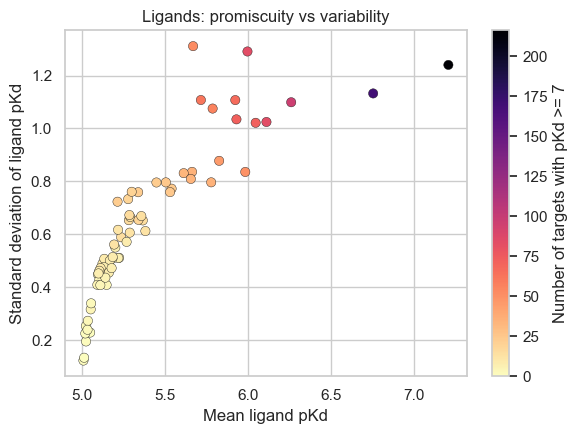

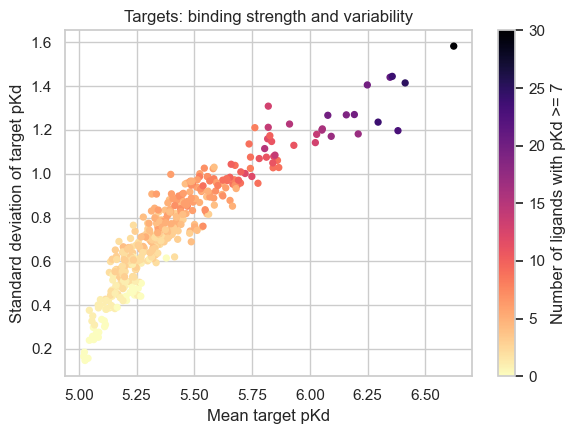

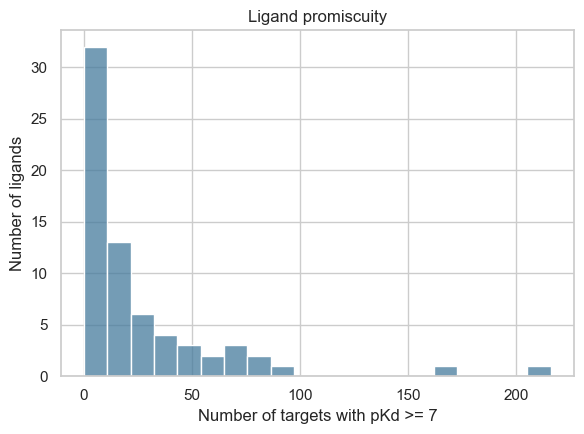

<Figure size 640x480 with 0 Axes>

Most promiscuous ligands


,mean,std,n_obs,n_above_limit,n_strong (pKd >= 7),smiles
lig_key,,,,,,
44259,7.207138,1.240173,379,350,216,CC12C(C(CC(O1)N3C4=CC=CC=C4C5=C6C(=C7C8=CC=CC=C8N2C7=C5
126565,6.754232,1.132327,379,342,169,CC12C(CC(O1)N3C4=CC=CC=C4C5=C6C(=C7C8=CC=CC=C8N2C7=C53)
16038120,6.260502,1.099083,379,292,97,CC(C)S(=O)(=O)C1=CC=CC=C1NC2=NC(=NC=C2Cl)NC3=C(C=C(C=C3
42642645,5.997181,1.290921,379,192,84,COC1=CC2=C(C=CN=C2C=C1OCCCN3CCOCC3)OC4=C(C=C(C=C4)NC(=O
11984591,6.111510,1.024405,379,257,84,CC1(C(=O)NC2=C(O1)C=CC(=N2)NC3=NC(=NC=C3F)NC4=CC(=C(C(=


Most selective / inactive ligands


,mean,std,n_obs,n_above_limit,n_strong (pKd >= 7),smiles
lig_key,,,,,,
9926054,5.049866,0.228440,379,25,0,CC1=CC2=C(C=C1)N=C(C3=NC=C(N23)C)NCCN.Cl
6918454,5.013389,0.133179,379,5,0,C1CC1CONC(=O)C2=C(C(=C(C=C2)F)F)NC3=C(C=C(C=C3)I)Cl
9929127,5.024935,0.194809,379,8,1,CC1=C(C=CC=N1)C(=O)NC2=C3C(=CC(=C2OC)Cl)C4=C(N3)C=NC=C4
10127622,5.009364,0.122625,379,3,1,CN1C=NC2=C1C=C(C(=C2F)NC3=C(C=C(C=C3)Br)Cl)C(=O)NOCCO
24779724,5.020394,0.225017,379,8,1,CN1C=C(C=N1)C2=NN3C(=NN=C3SC4=CC5=C(C=C4)N=CC=C5)C=C2


Most bindable targets


,mean,std,n_obs,n_above_limit,n_strong (pKd >= 7)
tgt_key,,,,,
PDGFRB,6.622226,1.582720,68,44,30
CSF1R,6.412014,1.414650,68,43,25
YSK4,6.380893,1.196530,68,50,23
PDGFRA,6.356147,1.444598,68,42,24
DDR1,6.346722,1.440585,68,43,21


In [40]:
# 1. Calculate binding statistics for each ligand or target
from matplotlib import axes


def stats(matrix, axis):

    # summary stats for row / column
    summary = pd.DataFrame({
        "mean": matrix.mean(axis = axis),
        "std": matrix.std(axis = axis),
        "n_obs": matrix.notna().sum(axis = axis),
        "n_above_limit": (matrix > LIMIT_PKD + 1e-9).sum(axis = axis),
        "n_strong (pKd >= 7)": (matrix >= 7).sum(axis = axis)
    })
    return summary


# Calculate statistics for each ligand and each target
lig_stats = stats(pkd_matrix, axis = 1)
tgt_stats = stats(pkd_matrix, axis = 0)


# 2. graph out ligand and target behaviour
plt.figure(figsize = (6, 4.5))
ligand_scatter = plt.scatter(
    lig_stats["mean"],
    lig_stats["std"],
    c = lig_stats["n_strong (pKd >= 7)"],
    cmap = "magma_r",
    s = 45,
    edgecolor = "k",
    linewidth = 0.3
)

plt.colorbar(
    ligand_scatter,
    label="Number of targets with pKd >= 7"
)
plt.xlabel("Mean ligand pKd")
plt.ylabel("Standard deviation of ligand pKd")
plt.title("Ligands: promiscuity vs variability")
plt.tight_layout()
plt.show()


# Plot 2: Target binding strength and variability
plt.figure(figsize = (6, 4.5))
target_scatter = plt.scatter(
    tgt_stats["mean"],
    tgt_stats["std"],
    c = tgt_stats["n_strong (pKd >= 7)"],
    cmap = "magma_r",
    s = 18
)

plt.colorbar(
    target_scatter,
    label="Number of ligands with pKd >= 7"
)
plt.xlabel("Mean target pKd")
plt.ylabel("Standard deviation of target pKd")
plt.title("Targets: binding strength and variability")
plt.tight_layout()
plt.show()


# Plot 3: Distribution of strong-binding target counts per ligand
plt.figure(figsize = (6, 4.5))

sns.histplot(
    lig_stats["n_strong (pKd >= 7)"],
    bins = 20,
    color = "#457b9d"
)

plt.xlabel("Number of targets with pKd >= 7")
plt.ylabel("Number of ligands")
plt.title("Ligand promiscuity")
plt.tight_layout()
plt.show()


# Adjust spacing and display all three plots
plt.tight_layout()
plt.show()


# 3. best ligands
# get shortened SMILES representation for each ligand
short_smiles = lambda cid: ligands[cid][:55]

# sort ligands by the most number of strong binding targets
best_ligands = lig_stats.sort_values(
    "n_strong (pKd >= 7)",
    ascending = False
)
print("Most promiscuous ligands")
display(
    best_ligands.head(5).assign(
        smiles = [
            short_smiles(cid)
            for cid in best_ligands.head(5).index
        ]
    )
)


# 4. worst ligands
# Sort ligands from the fewest strong-binding targets to the most
bad_ligands = lig_stats.sort_values("n_strong (pKd >= 7)", ascending = True)

print("Most selective / inactive ligands")
display(
    bad_ligands.head(5).assign(
        smiles = [
            short_smiles(cid)
            for cid in bad_ligands.head(5).index
        ]
    )
)


# 5. most bindable targets
targets_by_mean_affinity = tgt_stats.sort_values("mean", ascending = False)

print("Most bindable targets")
display(targets_by_mean_affinity.head(5))

#### PCA and clustering of score matrix

fit the pkd matrix into PCA then plot ligands and targets in PCA space

part 6 attempts to use k-means to determine if the ligands can be clustered together based on their binding profiles

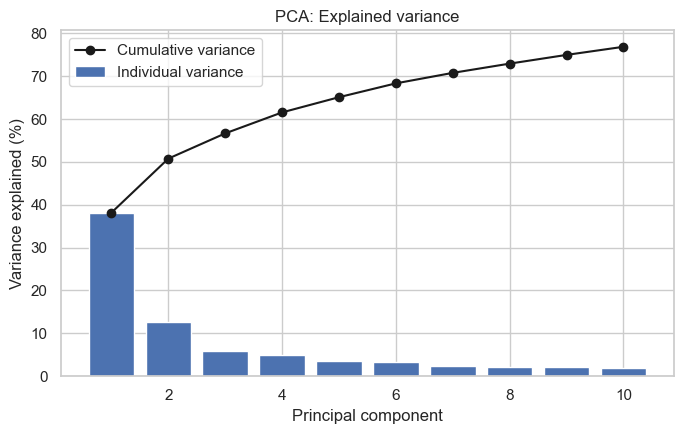

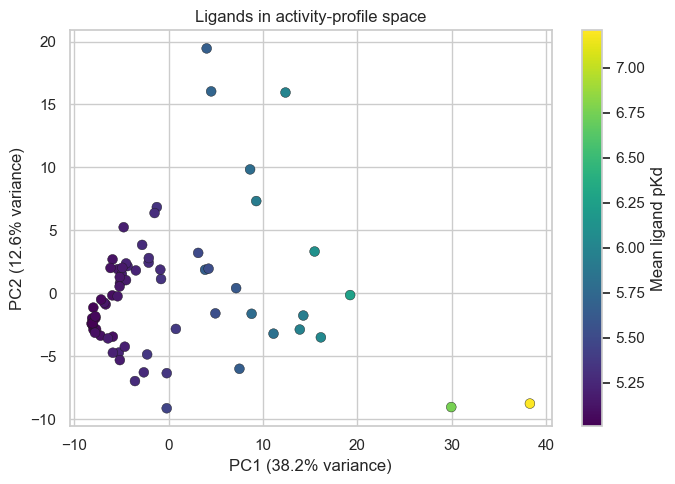

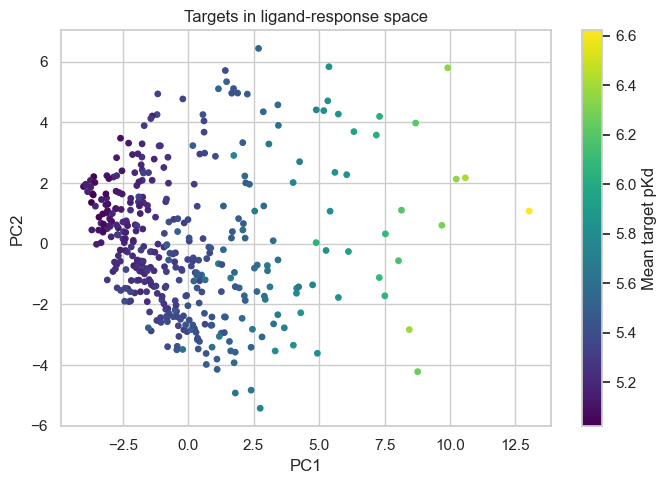

PC1 and PC2 explain 50.8% of the variance.
Components needed for 80% variance: 12
Components needed for 90% variance: 23
K-means silhouette scores: {2: np.float64(0.336), 3: np.float64(0.325), 4: np.float64(0.337), 5: np.float64(0.123), 6: np.float64(0.139), 7: np.float64(0.138), 8: np.float64(0.122)}


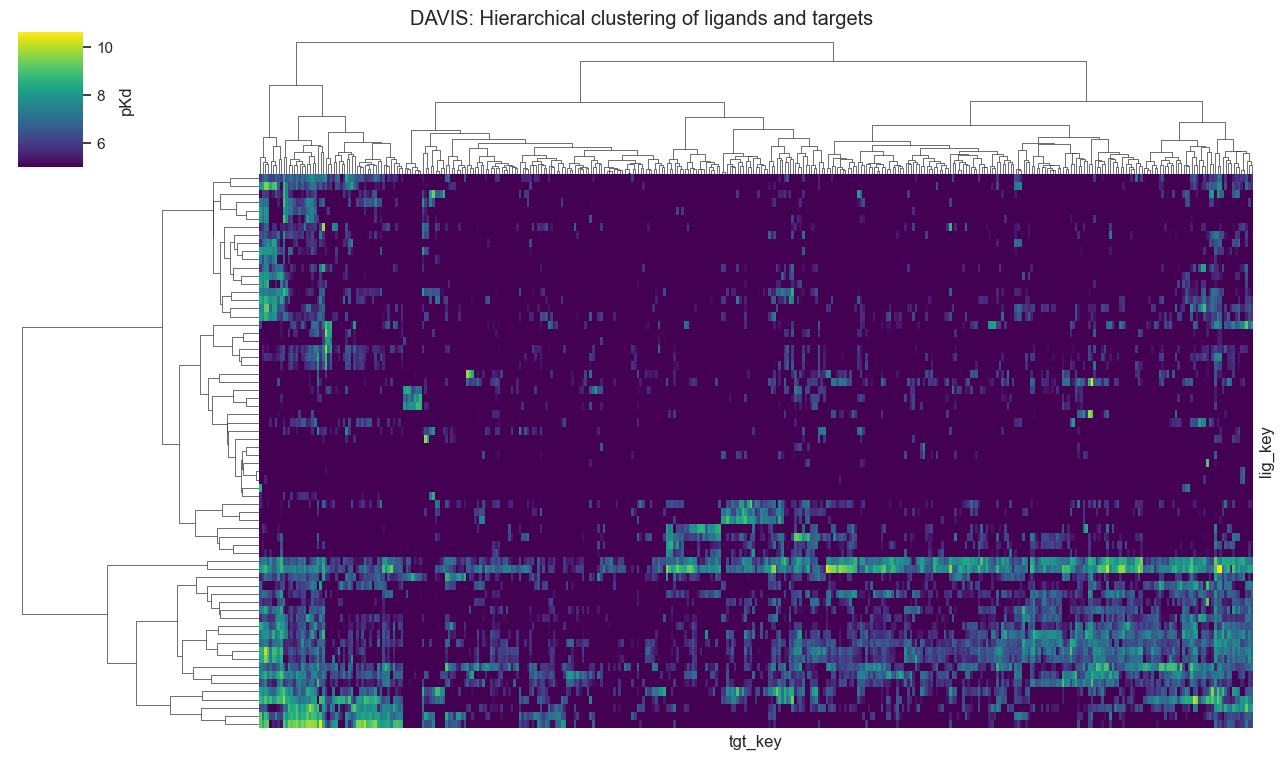

In [42]:
# center by subtracting mean of each col
centred_data = pkd_matrix.values - pkd_matrix.values.mean(axis = 0, keepdims = True)

# fit PCA and transform ligand profiles into principal component space
pca = PCA(random_state = SEED)
ligand_pca_coordinates = pca.fit_transform(centred_data)

# proportion of variance explained by each component
explained_variance = pca.explained_variance_ratio_

# 2. graph explained variance

# first 10 components
component_numbers = range(1, 11)

plt.figure(figsize = (7, 4.5))
plt.bar(
    component_numbers,
    explained_variance[:10] * 100,
    label="Individual variance"
)
plt.plot(
    component_numbers,
    np.cumsum(explained_variance[:10]) * 100,
    "ko-",
    label="Cumulative variance"
)

plt.xlabel("Principal component")
plt.ylabel("Variance explained (%)")
plt.title("PCA: Explained variance")
plt.legend()
plt.tight_layout()
plt.show()

# 3. Plot ligands in PCA space
plt.figure(figsize = (7, 5))
ligand_scatter = plt.scatter(
    ligand_pca_coordinates[:, 0],
    ligand_pca_coordinates[:, 1],
    c = lig_stats["mean"],
    cmap = "viridis",
    s = 50,
    edgecolor = "k",
    linewidth = 0.3
)

plt.colorbar(
    ligand_scatter,
    label = "Mean ligand pKd"
)

plt.xlabel(f"PC1 ({explained_variance[0]:.1%} variance)")
plt.ylabel(f"PC2 ({explained_variance[1]:.1%} variance)")
plt.title("Ligands in activity-profile space")
plt.tight_layout()
plt.show()


# 4. Plot targets in PCA space
# Transpose the matrix so each target is represented by its ligand-response profile
target_data = pkd_matrix.values.T

# Centre each ligand column across targets
centred_target_data = (
    target_data - target_data.mean(axis = 0, keepdims = True)
)

# Calculate two principal components for the targets
target_pca = PCA(n_components = 2, random_state = SEED)
target_pca_coordinates = target_pca.fit_transform(centred_target_data)

plt.figure(figsize = (7, 5))
target_scatter = plt.scatter(
    target_pca_coordinates[:, 0],
    target_pca_coordinates[:, 1],
    c = tgt_stats["mean"],
    cmap = "viridis",
    s = 15
)

plt.colorbar(
    target_scatter,
    label="Mean target pKd"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Targets in ligand-response space")
plt.tight_layout()
plt.show()


# 5. PCA results

cumulative_variance = np.cumsum(explained_variance)

# Find how many components are needed to explain 80% and 90% of variance
components_for_80_percent = np.searchsorted(
    cumulative_variance, 0.80
) + 1

components_for_90_percent = np.searchsorted(
    cumulative_variance, 0.90
) + 1

print(
    f"PC1 and PC2 explain {cumulative_variance[1]:.1%} of the variance."
)

print(
    f"Components needed for 80% variance: "
    f"{components_for_80_percent}"
)

print(
    f"Components needed for 90% variance: "
    f"{components_for_90_percent}"
)


# 6. try to do k-means on the ligands
cluster_numbers = range(2, 9)
silhouette_scores = []

for number_of_clusters in cluster_numbers:

    # Assign each ligand to a cluster
    cluster_labels = KMeans(
        n_clusters=number_of_clusters,
        n_init=10,
        random_state=SEED
    ).fit_predict(centred_data)

    # evaluate clusters
    score = silhouette_score(centred_data, cluster_labels)
    silhouette_scores.append(score)


# silhouette score for each cluster
clustering_results = {
    number_of_clusters: round(score, 3)
    for number_of_clusters, score
    in zip(cluster_numbers, silhouette_scores)
}

print("K-means silhouette scores:", clustering_results)

# 7. Plot hierarchical clustering of ligands and targets
clustered_heatmap = sns.clustermap(
    pkd_matrix,
    cmap = "viridis",
    method = "ward",
    figsize = (13, 7.5),
    xticklabels = False,
    yticklabels = False,
    cbar_kws = {"label": "pKd"}
)

clustered_heatmap.fig.suptitle(
    "DAVIS: Hierarchical clustering of ligands and targets",
    y=1.01
)

plt.show()